# 5.3 การเปรียบเทียบแผนและทางเลือกนโยบาย

ทุกแผนถูกประเมินด้วยทุกตัวหาร (ประชากร ทะเบียนสิทธิ บริการ ความจำเป็นอ้างอิง M5 และบริการที่ตอบสนองทรัพยากร)
ความต่างถูกแปลเป็นจำนวนแพทย์ที่ต้องเปลี่ยนจังหวัดปลายทาง จังหวัด และปี เกณฑ์ "ใกล้เคียงเชิงปฏิบัติ" ถูกกำหนดใน config ก่อนอ่านผล

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "chapter5.toml").exists())
sys.path.insert(0, str(_root / "src"))
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
pd.options.display.max_columns = 40
pd.options.display.width = 200
from chapter5 import config as C, pipeline as PL, allocation as AL, simulation as SIM, responsibilities as R
S = C.load()
D = S.dirs()
tab = lambda n, f="tables": pd.read_csv(D[f] / f"{n}.csv", encoding="utf-8-sig")
print("scenario:", S.name, "| config_hash:", S.hash())

scenario: canonical | config_hash: 9634ed4e506743c4


In [2]:
print(json.dumps(S.cfg['evaluation'], ensure_ascii=False, indent=1))
display(tab('T53_MAIN_PLANS'))

{
 "plan_modes": [
  "fixed_schedule",
  "annual_replanning"
 ],
 "paired_random_paths": true,
 "main_simulation_runs": 500,
 "dev_simulation_runs": 40,
 "adaptive_simulation_runs": 60,
 "switch_threshold_pct": 5.0,
 "cumulative_shortfall_threshold_pct": 2.0,
 "worst_province_loss_threshold_pct": 5.0,
 "bottom_quartile": 19
}


,แผน,ตัวหาร,การโยกย้าย,เป้าหมาย,สถานะ,แพทย์ 2583,ความเพียงพอรวม 2583,กลุ่มล่าง 19 จังหวัด 2583,ต่ำสุด 2583,Gini 2583,การโยกย้ายสะสม (ครั้ง),สัดส่วนจังหวัด-ปีที่เพดานตึง
0,P-R,ประชากร,ไม่มี,"รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,30011,0.542,0.377,0.099,0.083,0,0.63
1,P-RT,ประชากร,"มี (≤2%/ปี, งบประเทศ 1%)","รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,30011,0.542,0.377,0.099,0.083,0,0.63
2,S-R,บริการที่เกิดขึ้น,ไม่มี,"รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,29976,0.541,0.415,0.120,0.058,0,0.49
3,S-RT,บริการที่เกิดขึ้น,"มี (≤2%/ปี, งบประเทศ 1%)","รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,29976,0.541,0.415,0.120,0.058,0,0.49
4,N-R,ความจำเป็นอ้างอิง M5,ไม่มี,"รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,30009,0.542,0.395,0.096,0.073,0,0.63
5,N-RT,ความจำเป็นอ้างอิง M5,"มี (≤2%/ปี, งบประเทศ 1%)","รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,30051,0.542,0.387,0.096,0.079,0,0.69


In [3]:
display(tab('T56_CROSS_EVALUATION'))
xe = tab('T5_CROSS_EVALUATION_LONG')
display(xe[xe.plan_id.isin(['P-R', 'S-R', 'N-R'])].pivot_table(index='plan_id', columns='criterion', values=['bottom_quartile_2040', 'regret_j_pct']).round(3))

,แผน,ประชากรทะเบียนราษฎร,ความจำเป็นอ้างอิง M5,ประชากรทะเบียนสิทธิ,บริการที่เกิดขึ้น,บริการตอบสนองทรัพยากร λ=1
0,P-R,0.395 / +0.1%,0.377 / +0.0%,0.381 / +0.0%,0.391 / +1.4%,0.418 (Gini 0.090)
1,P-RT,0.395 / +0.1%,0.377 / +0.0%,0.381 / +0.0%,0.391 / +1.4%,0.418 (Gini 0.090)
2,S-R,0.367 / +1.6%,0.350 / +1.8%,0.357 / +1.7%,0.415 / +0.0%,0.432 (Gini 0.057)
3,S-RT,0.367 / +1.6%,0.350 / +1.8%,0.357 / +1.7%,0.415 / +0.0%,0.432 (Gini 0.057)
4,N-R,0.395 / +0.0%,0.377 / +0.1%,0.386 / +0.1%,0.397 / +1.2%,0.422 (Gini 0.086)
5,N-RT,0.387 / +0.0%,0.373 / +0.1%,0.378 / +0.1%,0.391 / +1.2%,0.412 (Gini 0.088)
6,SQ-C,0.324 / +2.8%,0.314 / +3.2%,0.309 / +3.1%,0.348 / +1.5%,0.389 (Gini 0.103)
7,NFB1-R,0.376 / +1.0%,0.357 / +1.4%,0.363 / +1.3%,0.398 / +0.7%,0.422 (Gini 0.075)


bottom_quartile_2040                                     regret_j_pct                     
criterion                    N      P   Pent      S resp0.5  resp1            N      P   Pent      S
plan_id                                                                                             
N-R                      0.395  0.377  0.386  0.397   0.411  0.422        0.017  0.108  0.102  1.166
P-R                      0.395  0.377  0.381  0.391   0.406  0.418        0.134  0.000  0.000  1.351
S-R                      0.367  0.350  0.357  0.415   0.422  0.432        1.586  1.811  1.681  0.000

In [4]:
display(tab('T5_PRACTICAL_DIFFERENCES')[['plan_a', 'plan_b', 'mean_annual_switched', 'mean_annual_switched_pct', 'max_cum_receipts_diff', 'province_max_cum_diff', 'max_cumulative_shortfall_diff_pct', 'worst_bottom_quartile_loss_pct', 'practically_similar']])

,plan_a,plan_b,mean_annual_switched,mean_annual_switched_pct,max_cum_receipts_diff,province_max_cum_diff,max_cumulative_shortfall_diff_pct,worst_bottom_quartile_loss_pct,practically_similar
0,P-R,S-R,192.466667,9.623333,425,นนทบุรี,0.024923,-32.425026,False
1,P-R,N-R,119.066667,5.953333,75,ปัตตานี,0.003586,0.000000,False
2,S-R,N-R,199.733333,9.986667,386,นนทบุรี,0.028502,0.000000,False
3,P-RT,S-RT,192.466667,9.623333,425,นนทบุรี,0.024923,-32.425026,False
4,P-RT,N-RT,185.600000,9.280000,92,ราชบุรี,0.082039,-28.329972,False
5,S-RT,N-RT,237.600000,11.880000,413,นนทบุรี,0.106936,-0.426869,False
6,P-R,P-RT,0.000000,0.000000,0,สมุทรปราการ,0.000000,0.000000,True
7,S-R,S-RT,0.000000,0.000000,0,สมุทรปราการ,0.000000,0.000000,True
8,N-R,N-RT,180.533333,9.026667,40,สมุทรสงคราม,0.078456,-28.329972,False
9,P-R,SQ-C,296.200000,14.810000,348,นนทบุรี,0.055777,-47.698529,False


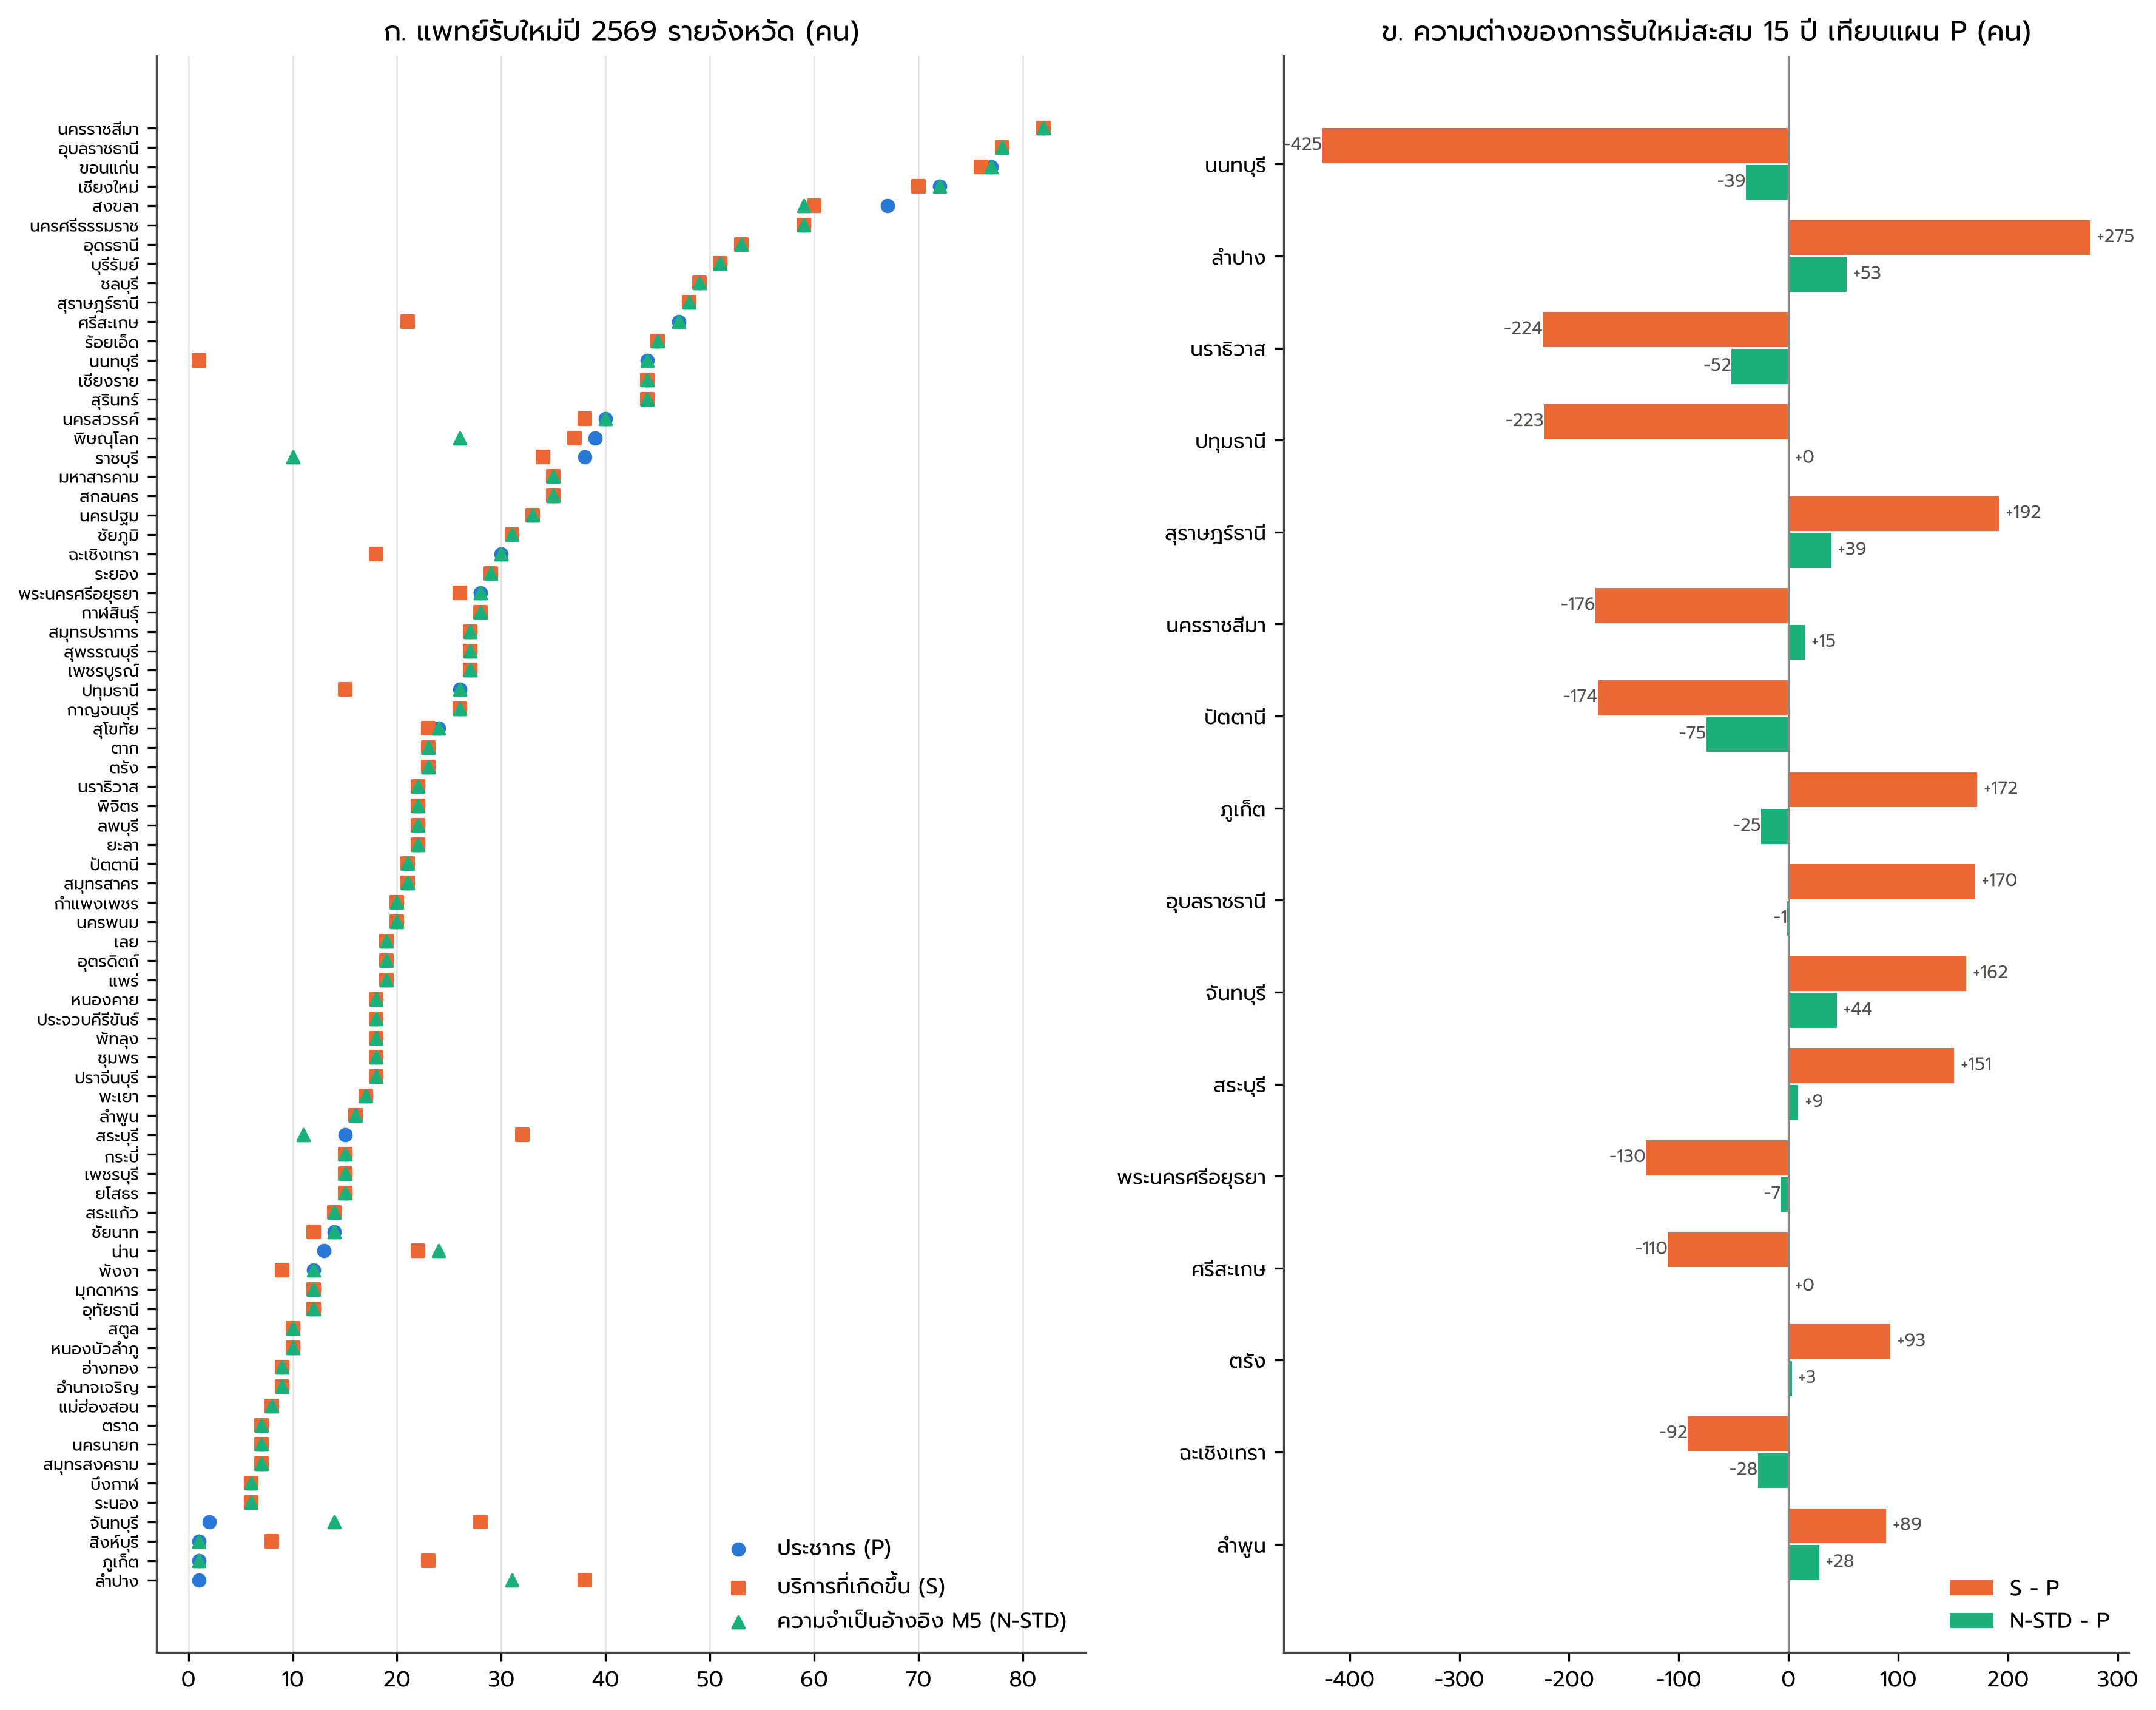

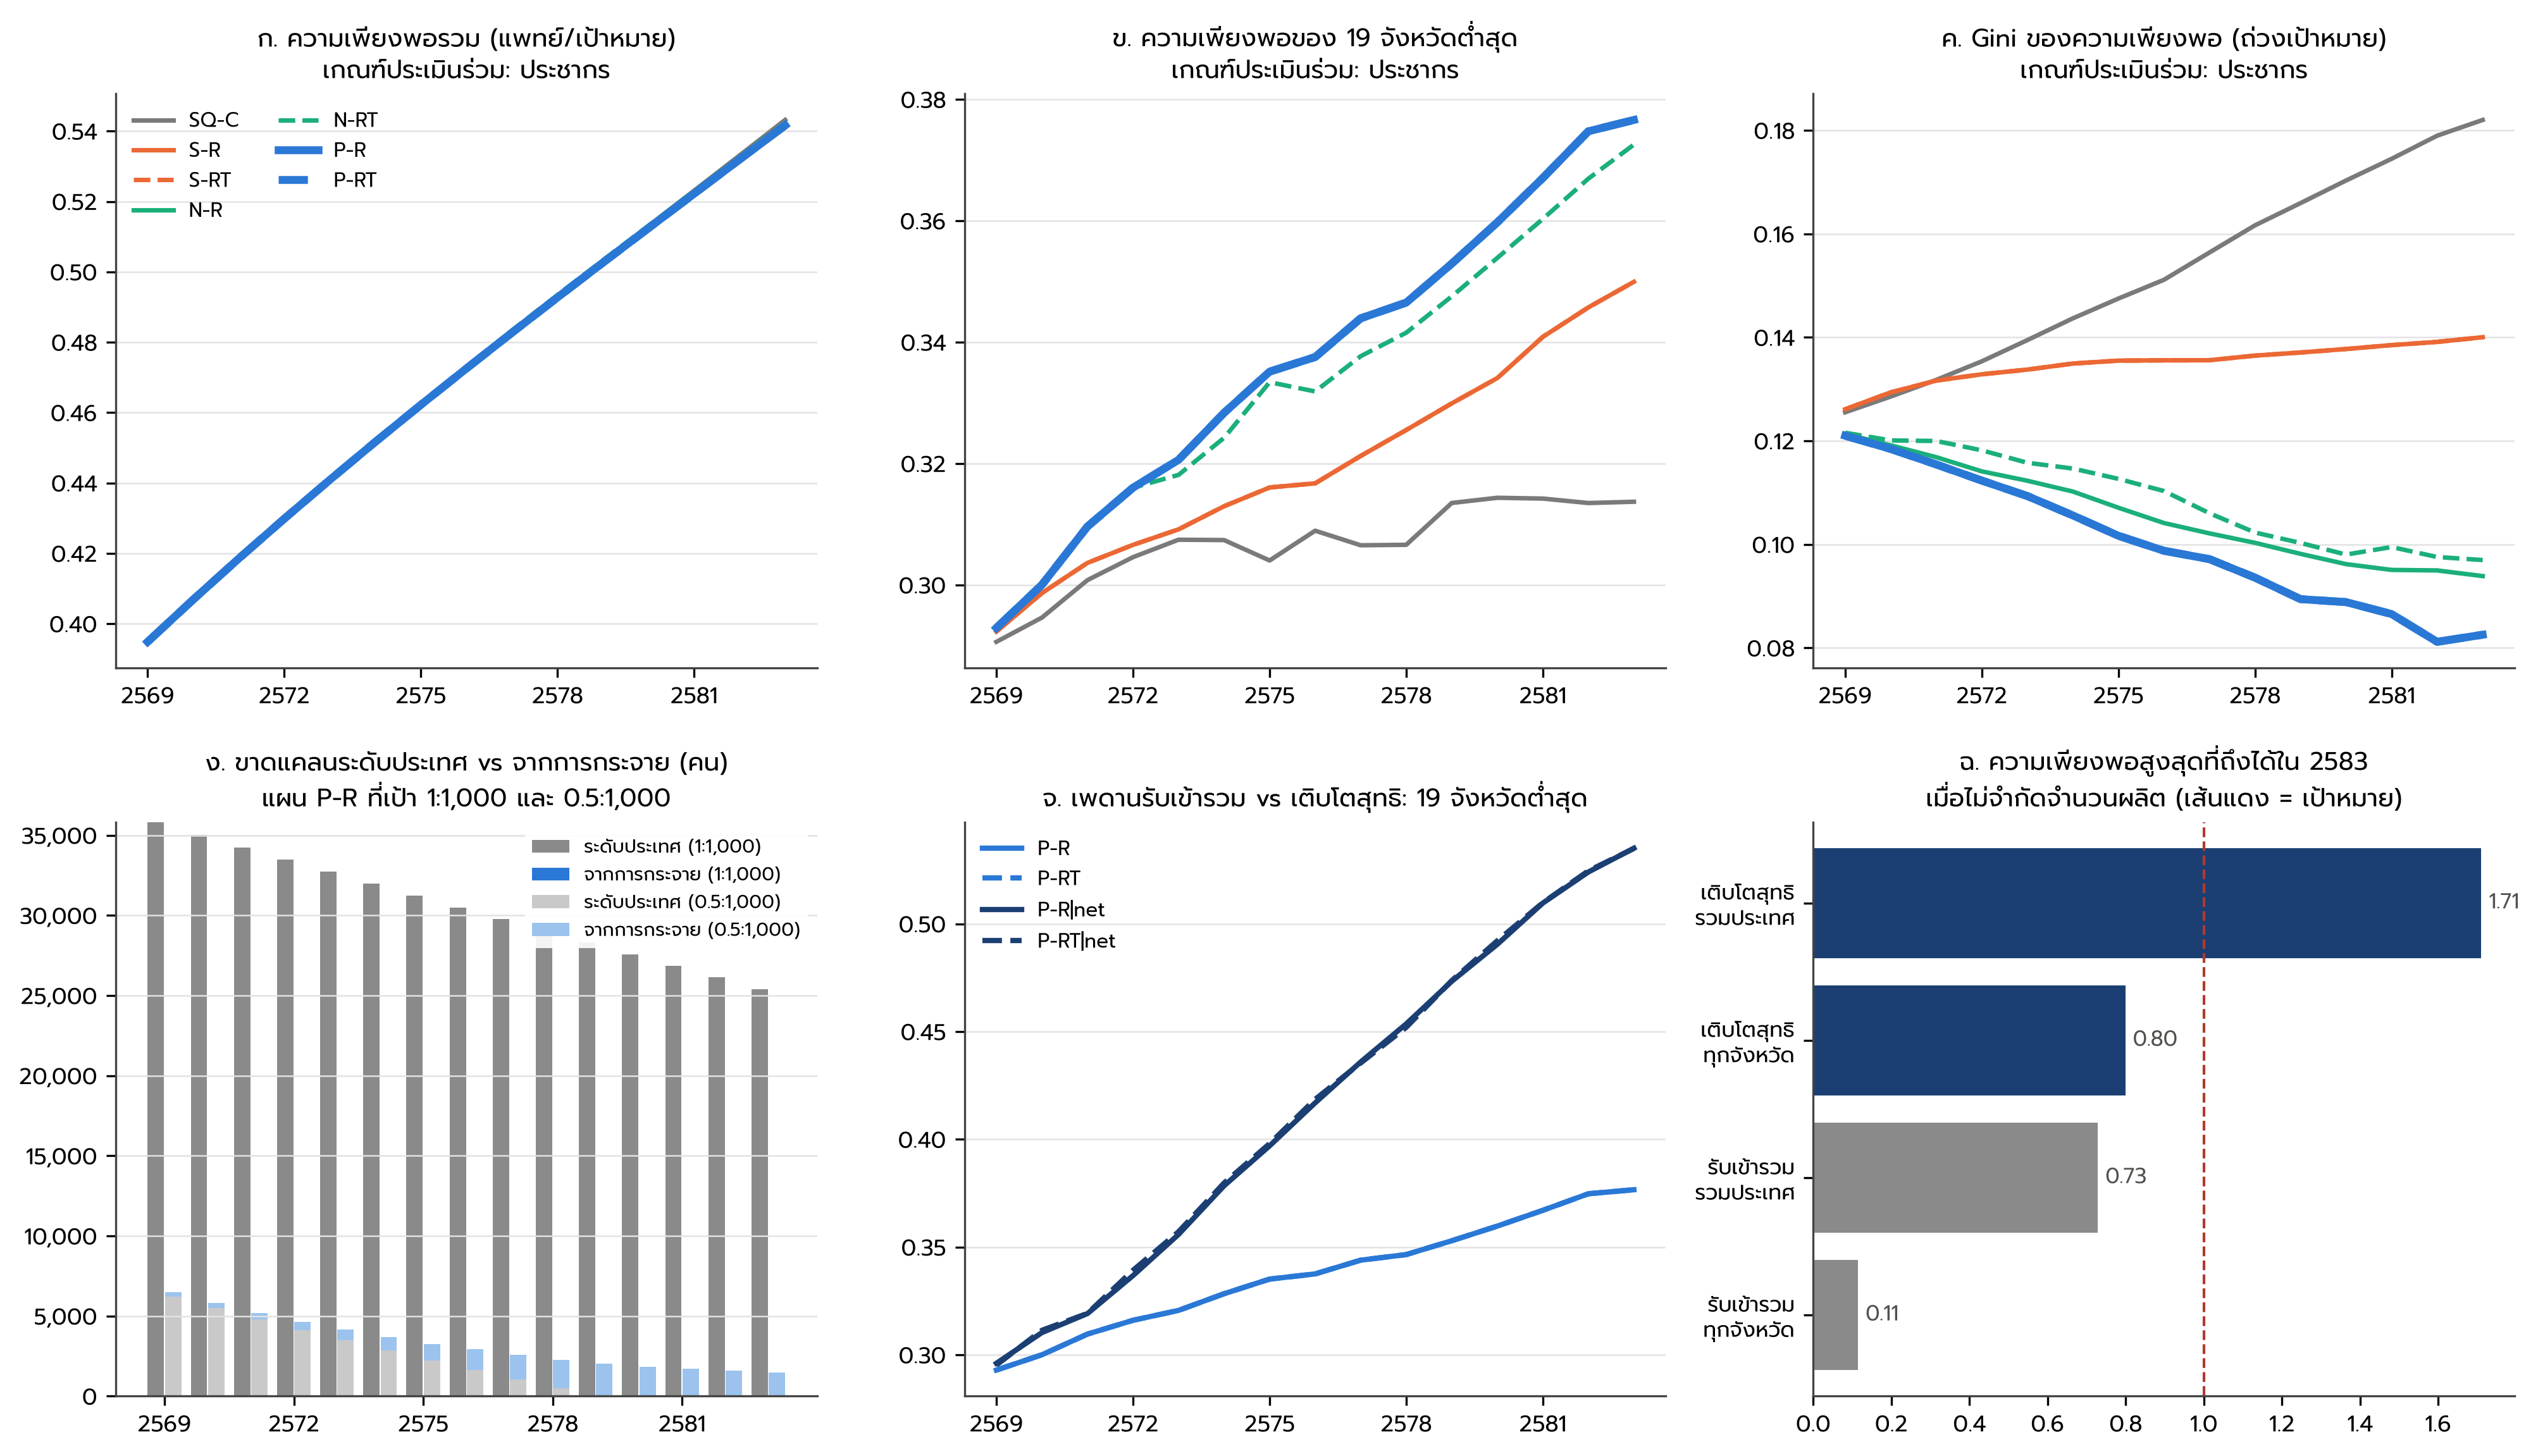

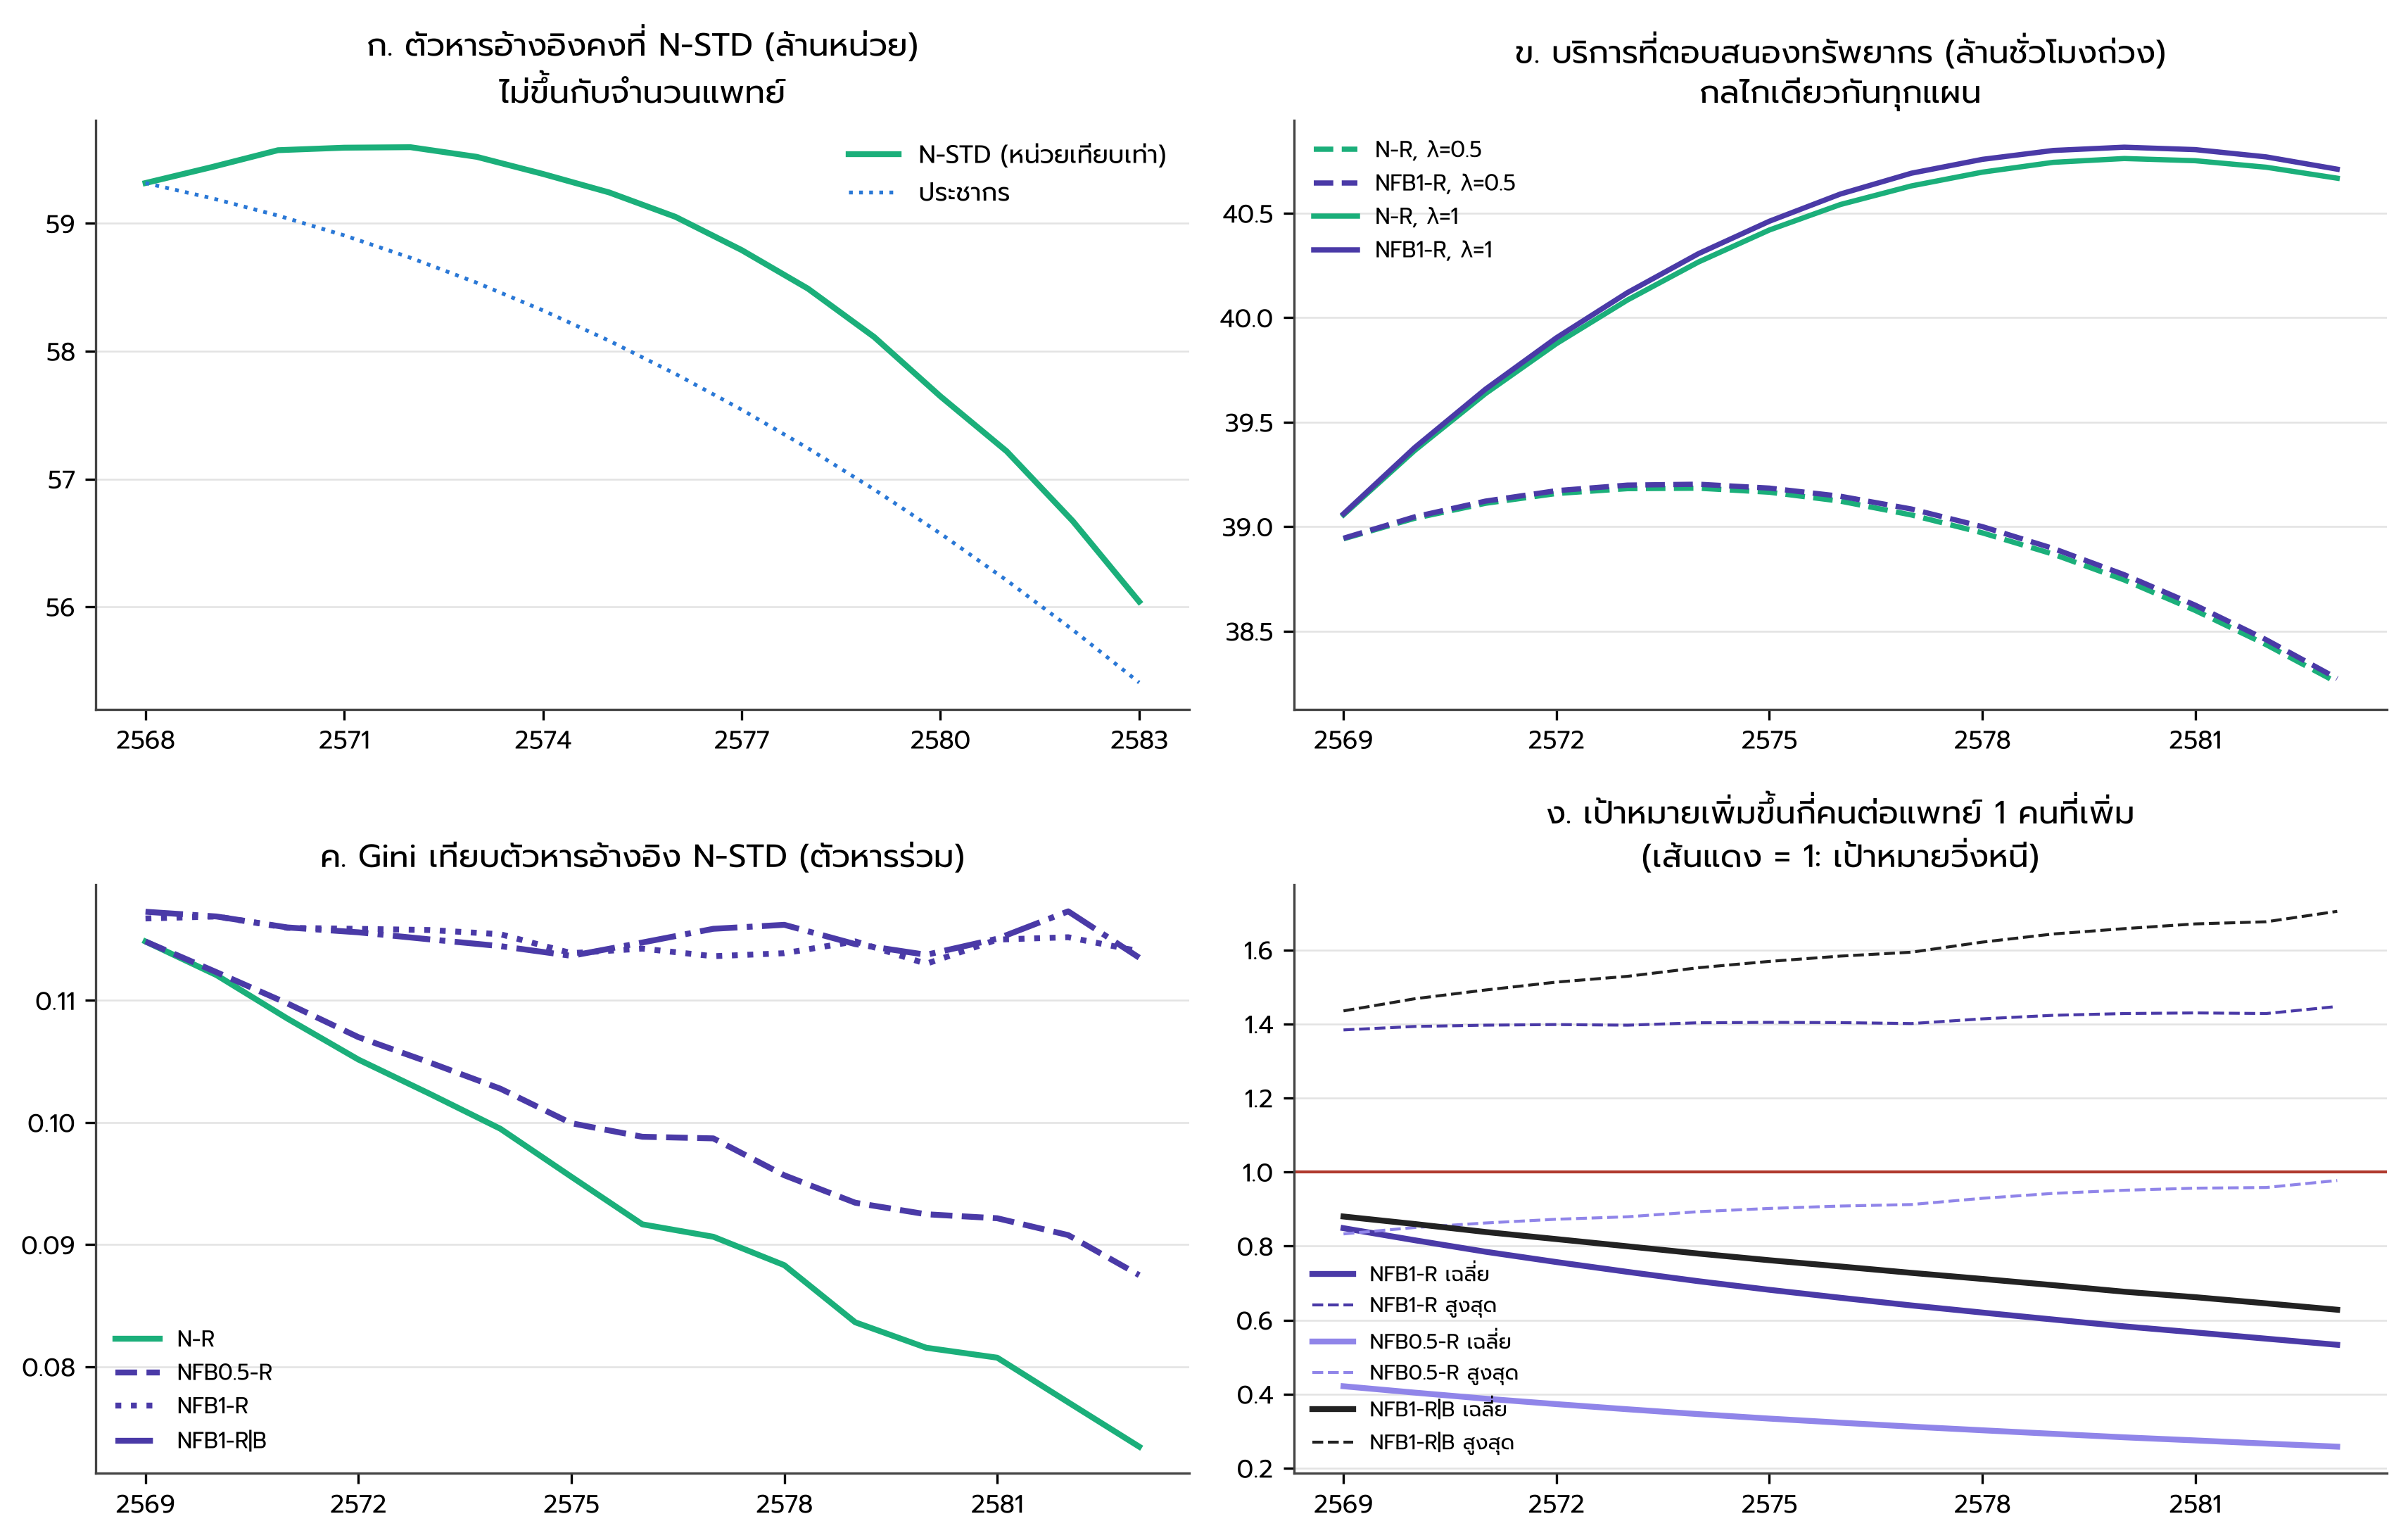

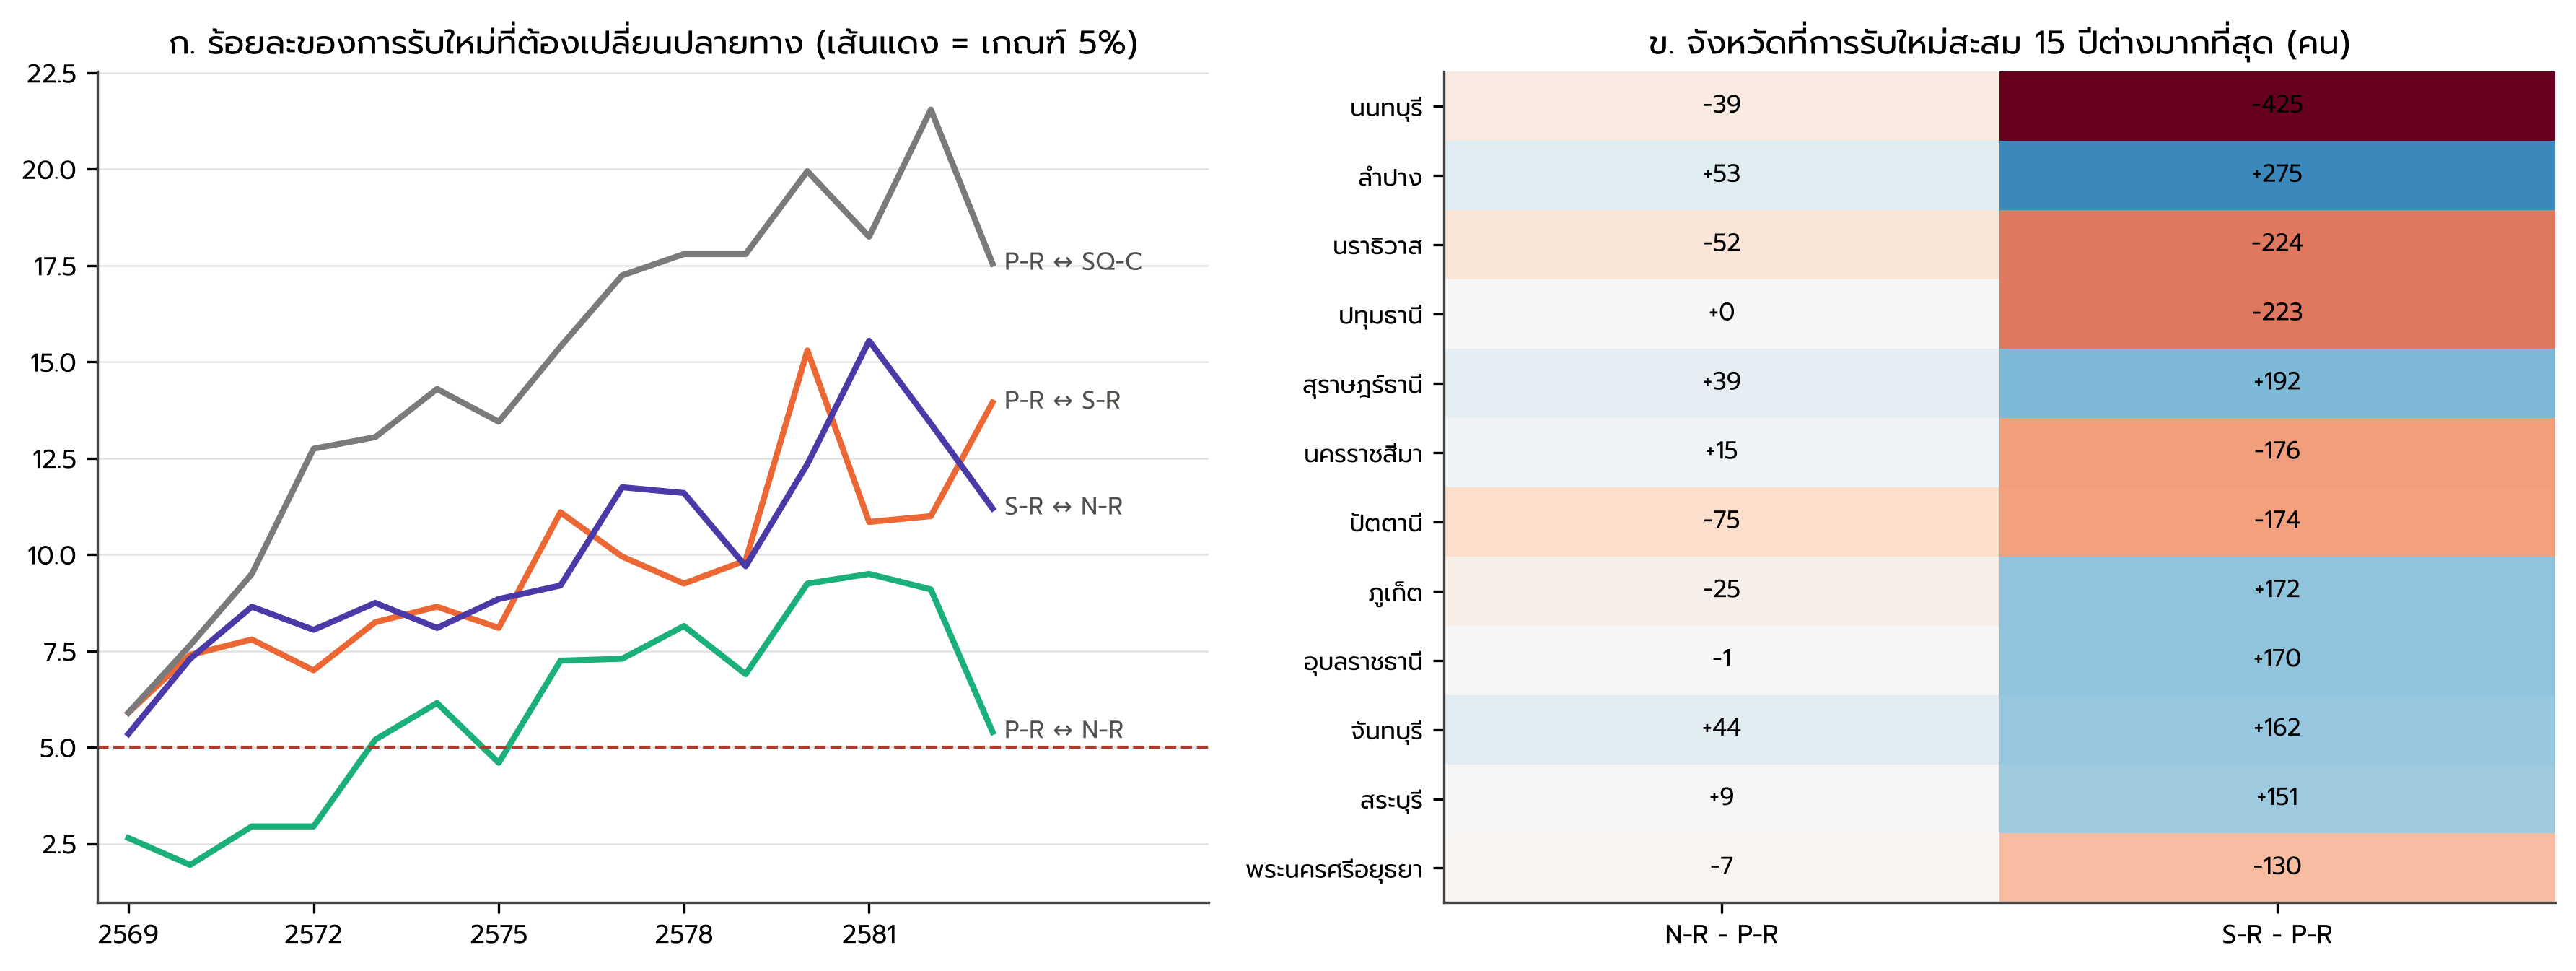

In [5]:
for f in ['F53_ANNUAL_ALLOCATIONS', 'F54_ADEQUACY_AND_INEQUALITY', 'F55_FEEDBACK', 'F56_PLAN_DISAGREEMENT']:
    display(Image(str(D['figures'] / f'{f}.png')))

## ข้อจำกัดที่ตึงตัว การโยกย้าย และความเป็นไปได้ย้อนกลับ

In [6]:
display(tab('T54_TRANSFER_AND_CAPACITY'))
display(tab('T5_INVERSE_FEASIBILITY'))
display(tab('T5_SENSITIVITY_SUMMARY'))

,แผน,เพดาน,สถานะ,การโยกย้ายสะสม (ครั้ง),จังหวัด-ปีที่เพดานตึง (%),จังหวัด-ปีที่ได้เพียงขั้นต่ำ (%),จำนวนที่จัดสรรไม่ได้,J เทียบแผนไม่มีโยกย้าย (%),แพทย์ 2583,จำนวนที่จัดสรรไม่ได้ (ขั้นต่ำ)
0,P-R,รับเข้ารวม 10%,exploratory_policy_scenario,0.0,63.3,1.1,0.0,NaN,30011.0,NaN
1,P-RT,รับเข้ารวม 10%,exploratory_policy_scenario,0.0,63.3,1.1,0.0,0.00,30011.0,NaN
2,S-RT,รับเข้ารวม 10%,exploratory_policy_scenario,0.0,49.2,0.3,0.0,0.00,29976.0,NaN
3,N-RT,รับเข้ารวม 10%,exploratory_policy_scenario,0.0,68.9,7.0,0.0,-0.02,30051.0,NaN
4,P-R|net,เติบโตสุทธิ 10%,exploratory_policy_scenario,0.0,10.0,6.0,0.0,NaN,29732.0,NaN
5,P-RT|net,เติบโตสุทธิ 10%,exploratory_policy_scenario,545.0,10.4,6.1,0.0,-0.01,29730.0,NaN
6,S-RT|net,เติบโตสุทธิ 10%,exploratory_policy_scenario,652.0,8.3,5.3,0.0,-0.01,29774.0,NaN
7,N-RT|net,เติบโตสุทธิ 10%,exploratory_policy_scenario,976.0,10.4,8.3,0.0,-0.06,29838.0,NaN
8,P-RT|tau0.05,รับเข้ารวม 10%,exploratory_policy_scenario,0.0,71.8,8.5,0.0,-0.01,30058.0,NaN
9,P-RT|net|tau0.05,เติบโตสุทธิ 10%,exploratory_policy_scenario,2602.0,10.7,8.4,0.0,-0.03,29732.0,NaN


,plan_id,cap_mode,criterion,ramp_limited,ramp_fraction,base_pool,reference_reachable_by_2040,total_appointments_required,pool_2040_required,max_attainment_2040,binding_province,note
0,INV|gross_arrivals,gross_arrivals,province,True,0.1,2000.0,False,NaN,NaN,0.114545,บึงกาฬ,LP relaxation of the recruitment-only problem;...
1,INV|gross_arrivals,gross_arrivals,province,False,NaN,2000.0,False,NaN,NaN,0.114545,บึงกาฬ,LP relaxation of the recruitment-only problem;...
2,INV|gross_arrivals,gross_arrivals,national,True,0.1,2000.0,False,NaN,NaN,0.728660,NaN,LP relaxation of the recruitment-only problem;...
3,INV|gross_arrivals,gross_arrivals,national,False,NaN,2000.0,False,NaN,NaN,0.728660,NaN,LP relaxation of the recruitment-only problem;...
4,INV|net_growth,net_growth,province,True,0.1,2000.0,False,NaN,NaN,0.798970,นนทบุรี,LP relaxation of the recruitment-only problem;...
5,INV|net_growth,net_growth,province,False,NaN,2000.0,False,NaN,NaN,0.798970,ปทุมธานี,LP relaxation of the recruitment-only problem;...
6,INV|net_growth,net_growth,national,True,0.1,2000.0,True,58063.0,6939.0,1.159112,NaN,LP relaxation of the recruitment-only problem;...
7,INV|net_growth,net_growth,national,False,NaN,2000.0,True,56556.0,7588.0,1.710276,NaN,LP relaxation of the recruitment-only problem;...


,plan_id,base_plan,variant,status,stock_2040,national_attainment_own_2040,bottom_quartile_own_2040,gini_own_2040,transfer_events,objective_exact,mean_annual_switch_pct_vs_base,cum_receipts_max_abs_diff_vs_base
0,P-RT|net,P-RT,net_growth_cap,exploratory_policy_scenario,29730.030924,0.536577,0.534969,0.001061,545.0,4.274493,20.383333,570.0
1,S-RT|net,S-RT,net_growth_cap,exploratory_policy_scenario,29774.313838,0.537377,0.535575,0.001256,652.0,4.260224,16.560000,214.0
2,N-RT|net,N-RT,net_growth_cap,exploratory_policy_scenario,29837.550427,0.538518,0.535594,0.003000,976.0,4.268871,25.190000,528.0
3,P-RT|tau0.05,P-RT,transfer_0.05,exploratory_policy_scenario,30058.134518,0.542499,0.374720,0.086284,0.0,4.353656,9.863333,52.0
4,P-RT|net|tau0.05,P-RT,net_growth_cap_transfer_0.05,exploratory_policy_scenario,29732.252637,0.536618,0.535512,0.000717,2602.0,4.273730,22.290000,329.0
5,S-RT|tau0.05,S-RT,transfer_0.05,exploratory_policy_scenario,29976.479078,0.541025,0.415305,0.057622,0.0,4.296392,0.000000,0.0
6,S-RT|net|tau0.05,S-RT,net_growth_cap_transfer_0.05,exploratory_policy_scenario,29856.399996,0.538858,0.535038,0.003301,6.0,4.259681,21.680000,202.0
7,N-RT|tau0.05,N-RT,transfer_0.05,exploratory_policy_scenario,30055.345578,0.542449,0.388760,0.078680,0.0,4.338998,9.906667,37.0
8,N-RT|net|tau0.05,N-RT,net_growth_cap_transfer_0.05,exploratory_policy_scenario,29685.377453,0.535772,0.535013,0.000557,644.0,4.273293,22.593333,536.0
9,P-RT|net|surplus,P-RT,surplus_only,exploratory_policy_scenario,29731.763185,0.536609,0.535086,0.000905,0.0,4.275106,19.986667,579.0


## แผนปีแรก (พ.ศ. 2569)
ตารางเต็ม 15 ปีอยู่ใน `outputs/chapter5/plans/chapter5_annual_allocation_plans.xlsx`

In [7]:
display(tab('T57_FIRST_YEAR_PLAN'))

,จังหวัด,เขต,ตั้งต้น 2568,ออกที่คาด,กลับเข้าที่คาด,รับใหม่ P-R,ปลายปี P-R,ความเพียงพอ P-R,รับใหม่ S-R,ปลายปี S-R,ความเพียงพอ S-R,รับใหม่ N-R,ปลายปี N-R,ความเพียงพอ N-R
0,น่าน,1,252.0,13.8,0.8,13,252.1,0.544,22,261.1,0.486,24,263.1,0.506
1,พะเยา,1,180.0,10.9,0.6,17,186.7,0.420,17,186.7,0.366,17,186.7,0.406
2,ลำปาง,1,399.0,20.0,1.8,1,381.8,0.556,38,418.8,0.395,31,411.8,0.538
3,ลำพูน,1,172.0,11.6,0.7,16,177.1,0.456,16,177.1,0.321,16,177.1,0.418
4,เชียงราย,1,469.0,33.5,2.0,44,481.5,0.417,44,481.5,0.349,44,481.5,0.397
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,ปัตตานี,12,220.0,9.7,0.5,21,231.7,0.311,21,231.7,0.447,21,231.7,0.374
72,พัทลุง,12,190.0,10.7,0.8,18,198.1,0.385,18,198.1,0.321,18,198.1,0.350
73,ยะลา,12,230.0,8.4,0.5,22,244.1,0.440,22,244.1,0.391,22,244.1,0.520
74,สงขลา,12,701.0,29.3,2.3,67,741.1,0.524,60,734.1,0.501,59,733.1,0.537


## เปลี่ยนสมมติฐานแล้วรันใหม่
ตัวอย่าง (เขียนไปยังโฟลเดอร์ฉากทัศน์แยก ไม่ทับผลหลัก):
```
PYTHONPATH=src .venv/bin/python -m chapter5.build --all --set supply.annual_path=2500 --name pool2500
PYTHONPATH=src .venv/bin/python -m chapter5.build --all --set allocation.cap_mode=net_growth --name netcap
```